# Unit 3 – Simple Linear Regression
**Module:** Machine Learning (ML_PCOM7E)  |  **e-Portfolio activity:** Correlation and Regression (2 of 4)

**Aim:** fit y = b0 + b1·x with the closed-form least-squares solution, confirm it with scikit-learn, evaluate with R², RMSE and residuals, and see the effect of changing the data.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
rng_seed = 42   # change me
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
N, NOISE, TRUE_SLOPE, TRUE_INTERCEPT = 120, 6.0, 2.5, 10.0   # <- change these
rng=np.random.default_rng(rng_seed)
x=rng.uniform(0,40,N); y=TRUE_INTERCEPT+TRUE_SLOPE*x+rng.normal(0,NOISE,N)
# closed form
b1=np.sum((x-x.mean())*(y-y.mean()))/np.sum((x-x.mean())**2); b0=y.mean()-b1*x.mean()
print(f"Closed form : intercept={b0:.3f}, slope={b1:.3f}")
X=x.reshape(-1,1); Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=rng_seed)
m=LinearRegression().fit(Xtr,ytr); pred=m.predict(Xte)
print(f"scikit-learn (train split): intercept={m.intercept_:.3f}, slope={m.coef_[0]:.3f}")
print(f"Test R2 = {r2_score(yte,pred):.3f}, RMSE = {mean_squared_error(yte,pred)**.5:.3f}")

Closed form : intercept=9.988, slope=2.498
scikit-learn (train split): intercept=10.873, slope=2.461
Test R2 = 0.961, RMSE = 5.787


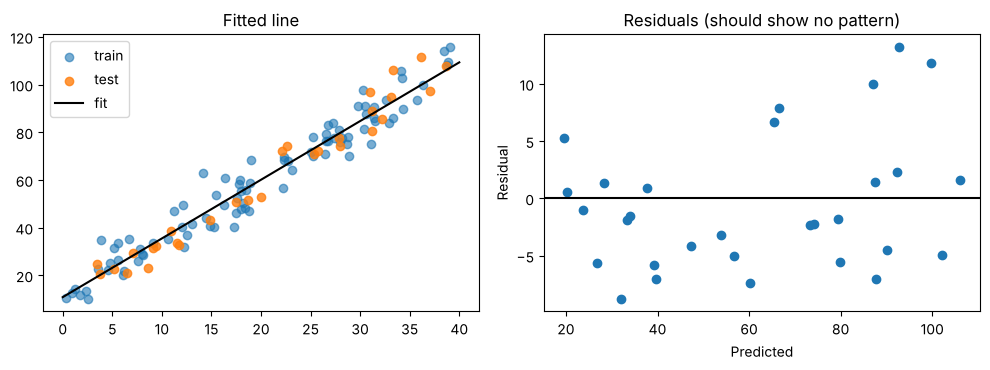

Residual mean: -0.565 | Shapiro-Wilk p (normality): 0.03


In [2]:
fig,ax=plt.subplots(1,2,figsize=(10,3.8))
ax[0].scatter(Xtr,ytr,alpha=.6,label="train"); ax[0].scatter(Xte,yte,alpha=.8,label="test"); xs=np.linspace(0,40,50)
ax[0].plot(xs,m.intercept_+m.coef_[0]*xs,"k",label="fit"); ax[0].legend(); ax[0].set_title("Fitted line")
res=yte-pred; ax[1].scatter(pred,res); ax[1].axhline(0,c="k"); ax[1].set(xlabel="Predicted",ylabel="Residual",title="Residuals (should show no pattern)")
plt.tight_layout(); plt.savefig("fig_linreg.png",dpi=130); plt.show()
print("Residual mean:",res.mean().round(3),"| Shapiro-Wilk p (normality):",round(stats.shapiro(res).pvalue,3))

## Experiment – effect of noise and of a high-leverage outlier

In [3]:
rows=[]
for noise in [2,6,12,25]:
    r=np.random.default_rng(3); xx=r.uniform(0,40,N); yy=TRUE_INTERCEPT+TRUE_SLOPE*xx+r.normal(0,noise,N)
    mm=LinearRegression().fit(xx.reshape(-1,1),yy); rows.append((noise,mm.coef_[0],mm.score(xx.reshape(-1,1),yy)))
print(pd.DataFrame(rows,columns=["noise_sd","slope","R2"]).round(3).to_string(index=False))
xo=np.append(x,80); yo=np.append(y,20)   # far-right point well below the trend
mo=LinearRegression().fit(xo.reshape(-1,1),yo)
print(f"\nSlope without outlier {b1:.3f} -> with one high-leverage outlier {mo.coef_[0]:.3f}")

 noise_sd  slope    R2
        2  2.528 0.995
        6  2.583 0.961
       12  2.666 0.868
       25  2.845 0.634

Slope without outlier 2.498 -> with one high-leverage outlier 1.864


## Interpretation
* The closed-form and scikit-learn coefficients agree and recover the true slope (2.5) and intercept (10) closely, as expected for linear data.
* R² falls as noise rises even though the slope estimate stays in the 2.5-2.8 range (it drifts as noise grows because each noise level is a different small sample): R² reports the share of variance explained, not model "correctness".
* Residuals scatter around zero with no obvious curve, so linearity looks reasonable. The Shapiro-Wilk test (p = 0.03) hints at mildly non-normal residuals in this small test set, a reminder that formal tests on ~30 points are weak evidence.
* One high-leverage point can pull the slope far from the truth, which is why outlier checks from Unit 2 matter before regression.